In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

# Load the data
df = pd.read_csv('../data/raw_sales.csv', encoding='ISO-8859-1')

print("Shape:", df.shape)
df.head()

Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [27]:
# Data types
print("Data Types:")
print(df.dtypes)
print("\n" + "="*50)

# Missing values
print("Missing Values:")
print(df.isnull().sum())
print("\n" + "="*50)

# Numeric summary
print("Numeric Summary:")
print(df.describe())
print("\n" + "="*50)

# Date range & unique counts
print("Date Range:", df['InvoiceDate'].min(), "to", df['InvoiceDate'].max())
print("Unique Countries:", df['Country'].nunique())
print("Unique Customers:", df['CustomerID'].nunique())
print("Unique Products:", df['StockCode'].nunique())

Data Types:
InvoiceNo          str
StockCode          str
Description        str
Quantity         int64
InvoiceDate        str
UnitPrice      float64
CustomerID     float64
Country            str
dtype: object

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Numeric Summary:
            Quantity      UnitPrice     CustomerID
count  541909.000000  541909.000000  406829.000000
mean        9.552250       4.611114   15287.690570
std       218.081158      96.759853    1713.600303
min    -80995.000000  -11062.060000   12346.000000
25%         1.000000       1.250000   13953.000000
50%         3.000000       2.080000   15152.000000
75%        10.000000       4.130000   16791.000000
max     80995.000000   38970.000000   18287.000000

Date Range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00
Unique Countries: 38
Unique Customers: 4372
Unique 

In [28]:
# ─── DATA CLEANING ───
print("Starting rows:", df.shape[0])
print("="*50)

# 1. Convert InvoiceDate to datetime
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
print("✓ Converted InvoiceDate to datetime")

# 2. Drop rows with missing CustomerID
df_clean = df.dropna(subset=['CustomerID']).copy()
print(f"✓ Dropped missing CustomerID: {df.shape[0] - df_clean.shape[0]} rows removed")

# 3. Remove cancellations (InvoiceNo starting with 'C')
before = df_clean.shape[0]
df_clean = df_clean[~df_clean['InvoiceNo'].astype(str).str.startswith('C')]
print(f"✓ Removed {before - df_clean.shape[0]} cancellations")

# 4. Remove negative or zero Quantity
before = df_clean.shape[0]
df_clean = df_clean[df_clean['Quantity'] > 0]
print(f"✓ Removed {before - df_clean.shape[0]} negative/zero Quantity rows")

# 5. Remove negative or zero UnitPrice
before = df_clean.shape[0]
df_clean = df_clean[df_clean['UnitPrice'] > 0]
print(f"✓ Removed {before - df_clean.shape[0]} negative/zero UnitPrice rows")

# 6. Remove non-product stock codes
non_products = ['POST', 'D', 'M', 'BANK CHARGES', 'DOT', 'CRUK', 'PADS', 'S']
before = df_clean.shape[0]
df_clean = df_clean[~df_clean['StockCode'].isin(non_products)]
print(f"✓ Removed {before - df_clean.shape[0]} non-product rows")

# 7. Convert CustomerID to integer
df_clean['CustomerID'] = df_clean['CustomerID'].astype(int)
print("✓ Converted CustomerID to integer")

# 8. Create Total_Revenue column
df_clean['Total_Revenue'] = df_clean['Quantity'] * df_clean['UnitPrice']
print("✓ Created Total_Revenue column")

# 9. Remove duplicate rows
before = df_clean.shape[0]
df_clean = df_clean.drop_duplicates()
print(f"✓ Removed {before - df_clean.shape[0]} duplicate rows")

print("\n" + "="*50)
print("Final rows:", df_clean.shape[0])
print("Rows removed:", df.shape[0] - df_clean.shape[0])
print("Removal %:", round((df.shape[0] - df_clean.shape[0]) / df.shape[0] * 100, 2), "%")
print("="*50)

Starting rows: 541909
✓ Converted InvoiceDate to datetime
✓ Dropped missing CustomerID: 135080 rows removed
✓ Removed 8905 cancellations
✓ Removed 0 negative/zero Quantity rows
✓ Removed 40 negative/zero UnitPrice rows
✓ Removed 1414 non-product rows
✓ Converted CustomerID to integer
✓ Created Total_Revenue column
✓ Removed 5187 duplicate rows

Final rows: 391283
Rows removed: 150626
Removal %: 27.8 %


C:\Users\User\AppData\Local\Temp\ipykernel_28524\3489170131.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_countries.values, y=top_countries.index, palette='viridis')


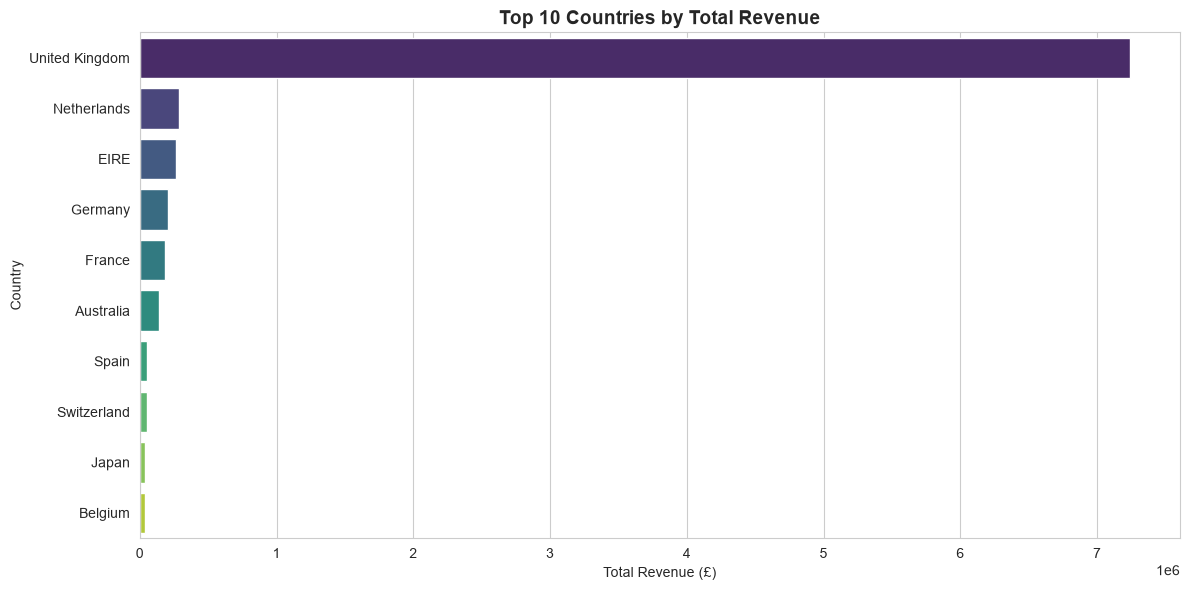


Top 10 Countries by Revenue:
Country
United Kingdom    7244330.32
Netherlands        283889.34
EIRE               261888.12
Germany            205381.15
France             183987.94
Australia          138103.81
Spain               55706.56
Switzerland         52441.95
Japan               37416.37
Belgium             36927.34
Name: Total_Revenue, dtype: float64


In [29]:
top_countries = df_clean.groupby('Country')['Total_Revenue'].sum().sort_values(ascending=False).head(10)
plt.figure(figsize=(12, 6))
sns.barplot(x=top_countries.values, y=top_countries.index, palette='viridis')
plt.title('Top 10 Countries by Total Revenue', fontsize=14, fontweight='bold')
plt.xlabel('Total Revenue (£)')
plt.ylabel('Country')
plt.tight_layout()
plt.savefig('../python/revenue_by_country.png', dpi=300, bbox_inches='tight')
plt.show()

print("\nTop 10 Countries by Revenue:")
print(top_countries)

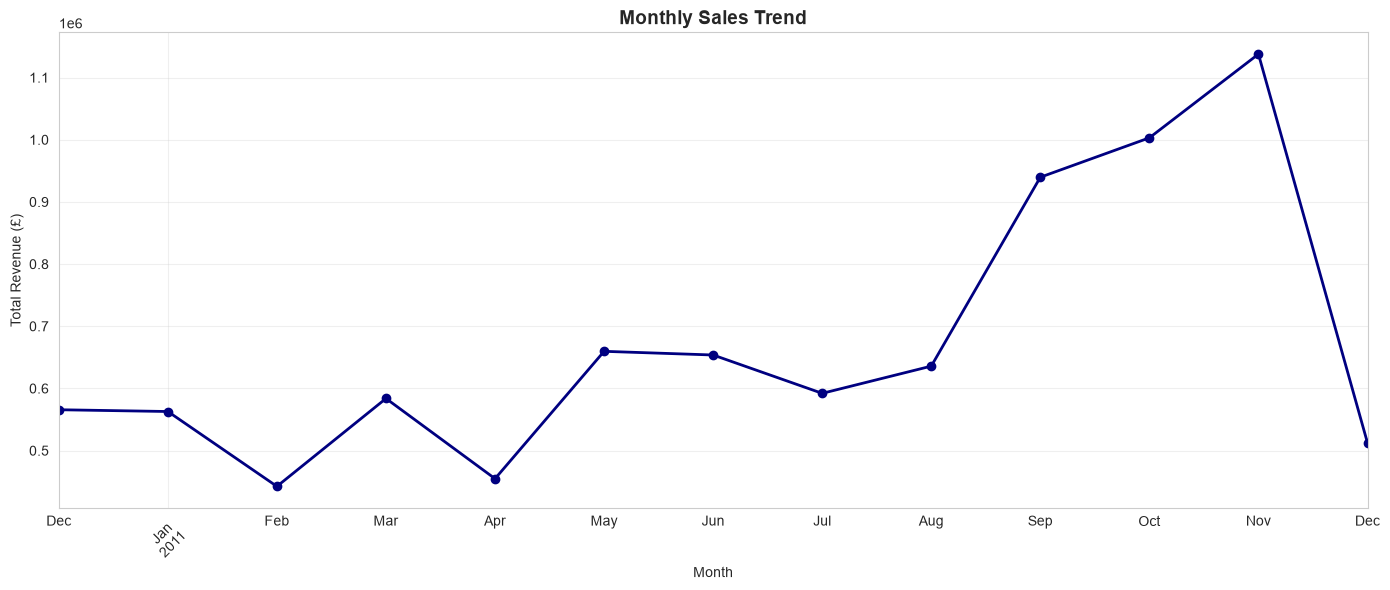


Monthly Sales:
Month
2010-12     565749.56
2011-01     562882.91
2011-02     442493.59
2011-03     583843.85
2011-04     454840.88
2011-05     659678.49
2011-06     653764.92
2011-07     592103.79
2011-08     635864.38
2011-09     939652.63
2011-10    1003026.56
2011-11    1137634.00
2011-12     512378.08
Freq: M, Name: Total_Revenue, dtype: float64


In [30]:
# Create Month column
df_clean['Month'] = df_clean['InvoiceDate'].dt.to_period('M')
monthly_sales = df_clean.groupby('Month')['Total_Revenue'].sum()

plt.figure(figsize=(14, 6))
monthly_sales.plot(kind='line', marker='o', color='navy', linewidth=2)
plt.title('Monthly Sales Trend', fontsize=14, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Total Revenue (£)')
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('monthly_trend.png', dpi=300, bbox_inches='tight')
plt.show()

print("\nMonthly Sales:")
print(monthly_sales)

C:\Users\User\AppData\Local\Temp\ipykernel_28524\3869640181.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_products.values, y=top_products.index, palette='coolwarm')


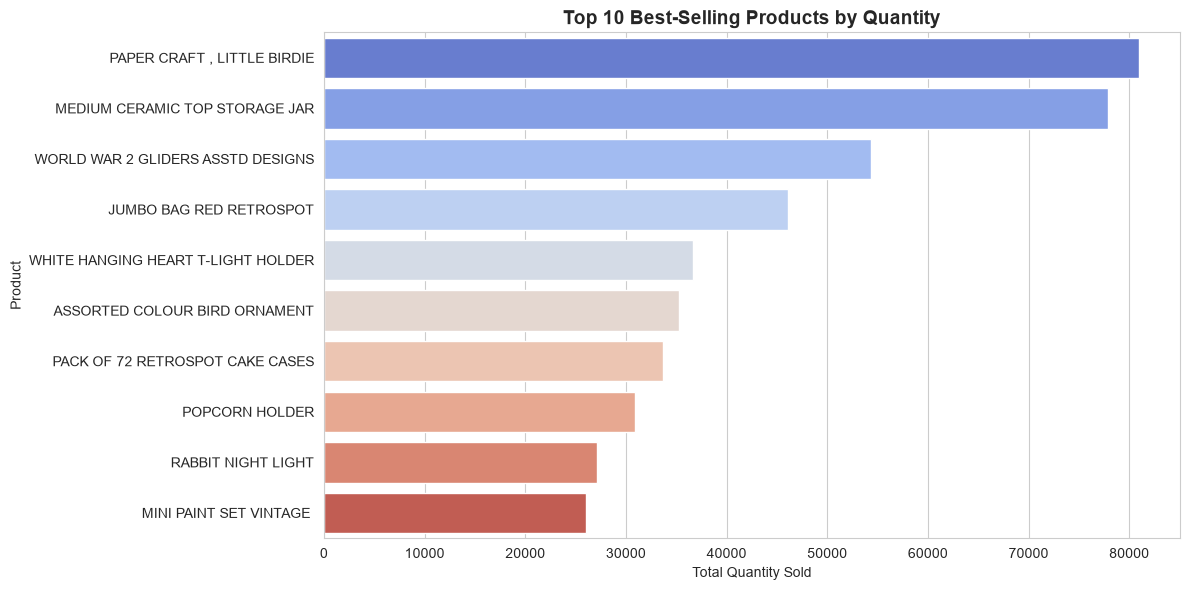


Top 10 Products by Quantity:
Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        77916
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54319
JUMBO BAG RED RETROSPOT               46078
WHITE HANGING HEART T-LIGHT HOLDER    36706
ASSORTED COLOUR BIRD ORNAMENT         35263
PACK OF 72 RETROSPOT CAKE CASES       33670
POPCORN HOLDER                        30919
RABBIT NIGHT LIGHT                    27153
MINI PAINT SET VINTAGE                26076
Name: Quantity, dtype: int64


In [31]:
top_products = df_clean.groupby('Description')['Quantity'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_products.values, y=top_products.index, palette='coolwarm')
plt.title('Top 10 Best-Selling Products by Quantity', fontsize=14, fontweight='bold')
plt.xlabel('Total Quantity Sold')
plt.ylabel('Product')
plt.tight_layout()
plt.savefig('top_products.png', dpi=300, bbox_inches='tight')
plt.show()

print("\nTop 10 Products by Quantity:")
print(top_products)

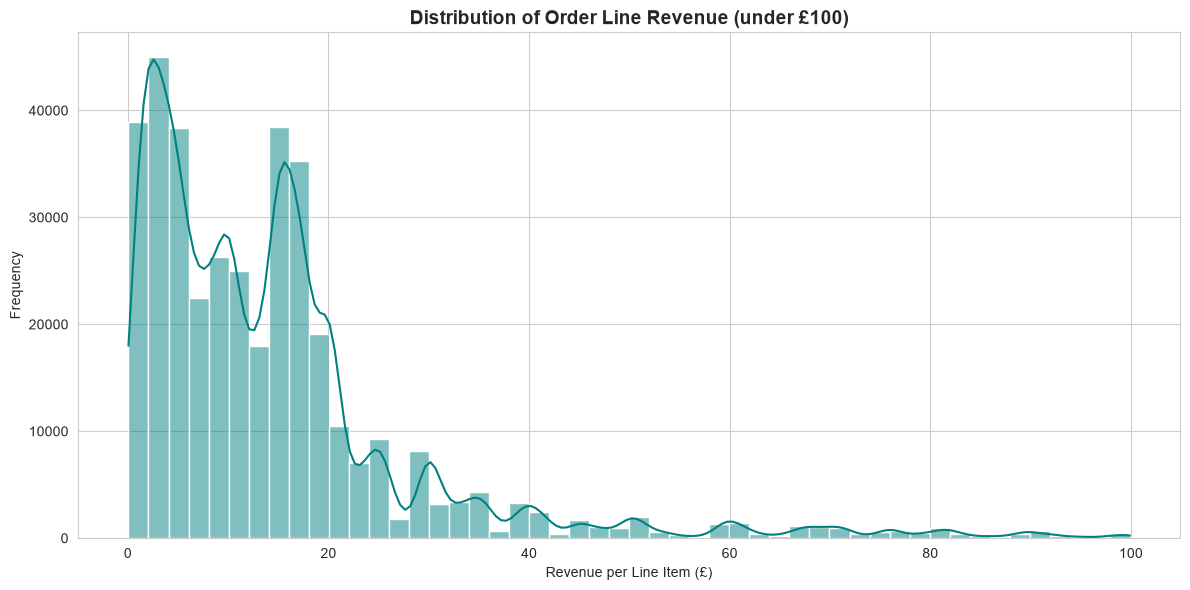


Revenue Distribution Stats:
count    391283.000000
mean         22.346776
std         310.880067
min           0.060000
25%           4.950000
50%          11.900000
75%          19.800000
max      168469.600000
Name: Total_Revenue, dtype: float64


In [32]:
plt.figure(figsize=(12, 6))
sns.histplot(df_clean[df_clean['Total_Revenue'] < 100]['Total_Revenue'], bins=50, kde=True, color='teal')
plt.title('Distribution of Order Line Revenue (under £100)', fontsize=14, fontweight='bold')
plt.xlabel('Revenue per Line Item (£)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.savefig('revenue_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

# Summary stats
print("\nRevenue Distribution Stats:")
print(df_clean['Total_Revenue'].describe())

In [33]:
df_clean.to_csv('../data/cleaned_sales.csv', index=False)
print("✅ Cleaned data saved!")
print("Final shape:", df_clean.shape)
print("\nColumns:", df_clean.columns.tolist())

✅ Cleaned data saved!
Final shape: (391283, 10)

Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'Total_Revenue', 'Month']
